# Quantum Kernels for Early Cancer Screening
**Quantum Machine Learning Challenge · Qiskit**

**Problem.** Classify breast biopsies as malignant or benign from 30 cell measurements (Breast Cancer Wisconsin, 569 samples).
**Quantum approach.** Compress to 4 features (PCA), encode each sample into a 4-qubit state with a Pauli feature map, use the state overlap as a **quantum kernel**, and train a classical SVM on it.
**Key idea.** The standard kernel is too expressive and fails (~71%). Tuning the kernel *bandwidth* (feature scaling) fixes it and gives a shallow, hardware-ready circuit.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix, ConfusionMatrixDisplay
from qiskit import QuantumCircuit
from qiskit.circuit.library import pauli_feature_map
from qiskit.quantum_info import Statevector
rng = np.random.default_rng(7)
X, y = load_breast_cancer(return_X_y=True)   # y: 0 = malignant, 1 = benign
print(X.shape, 'malignant:', (y==0).sum(), 'benign:', (y==1).sum())

(569, 30) malignant: 212 benign: 357


## 1. Preprocessing: 30 features → 4 qubits

In [2]:
def prep(Xtr, Xte, n=4):
    s = StandardScaler().fit(Xtr); p = PCA(n, random_state=0).fit(s.transform(Xtr))
    a, b = p.transform(s.transform(Xtr)), p.transform(s.transform(Xte))
    m = MinMaxScaler((0, np.pi)).fit(a)
    return m.transform(a), np.clip(m.transform(b), 0, np.pi)

## 2. The quantum feature map (the circuit)

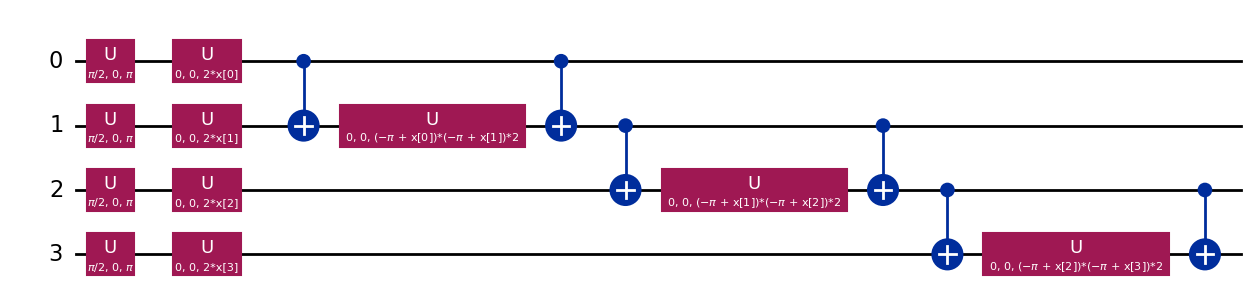

In [3]:
def feature_map(paulis=('Z','ZZ'), reps=1):
    return pauli_feature_map(4, reps=reps, paulis=list(paulis), entanglement='linear')
fm = feature_map()
fm.decompose().draw('mpl', fold=-1)

In [4]:
t = fm.decompose().decompose()
print('qubits', t.num_qubits, '| depth', t.depth(), '| ops', dict(t.count_ops()))

qubits 4 | depth 11 | ops {'u': 11, 'cx': 6}


## 3. Quantum kernel  k(x, x′) = |⟨ψ(x)|ψ(x′)⟩|²

In [5]:
def states(fm, X): return np.array([Statevector(fm.assign_parameters(x)).data for x in X])
def qkernel(fm, A, B):
    return np.abs(states(fm, A).conj() @ states(fm, B).T) ** 2

### Sanity check: the matrix kernel equals the circuit-based *compute–uncompute* kernel on the Aer simulator

In [6]:
from qiskit_aer import AerSimulator
sim = AerSimulator()
def circuit_kernel_entry(fm, x1, x2, shots=8192):
    qc = QuantumCircuit(4)
    qc.compose(fm.assign_parameters(x1), inplace=True)
    qc.compose(fm.assign_parameters(x2).inverse(), inplace=True)
    qc.measure_all()
    c = sim.run(qc.decompose().decompose(), shots=shots).result().get_counts()
    return c.get('0000', 0) / shots
Xa, _ = prep(X[:200], X[:5]); Xa = Xa[:4] * 0.1
exact = qkernel(fm, Xa, Xa)
circ = np.array([[circuit_kernel_entry(fm, a, b) for b in Xa] for a in Xa])
print('max |exact - circuit| =', np.abs(exact - circ).max().round(4))

max |exact - circuit| = 0.0084


## 4. Bandwidth matters: choosing the feature scale by inner cross-validation (training data only)

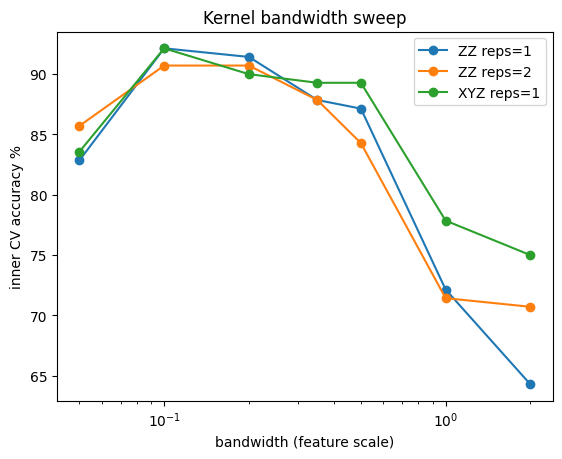

chosen bandwidth: 0.1


In [7]:
skf = StratifiedKFold(5, shuffle=True, random_state=1)
splits = [(rng.choice(tr,140,replace=False), rng.choice(te,100,replace=False)) for tr,te in skf.split(X,y)]
tr0 = splits[0][0]; A0, _ = prep(X[tr0], X[tr0]); y0 = y[tr0]
bws = [0.05, 0.1, 0.2, 0.35, 0.5, 1.0, 2.0]
sweep = {nm: [cross_val_score(SVC(kernel='precomputed', C=3), qkernel(f, A0*b, A0*b), y0, cv=5).mean()*100 for b in bws]
         for nm, f in {'ZZ reps=1': feature_map(), 'ZZ reps=2': feature_map(reps=2), 'XYZ reps=1': feature_map(('X','Y','ZZ'))}.items()}
for nm, v in sweep.items(): plt.plot(bws, v, 'o-', label=nm)
plt.xscale('log'); plt.xlabel('bandwidth (feature scale)'); plt.ylabel('inner CV accuracy %'); plt.legend(); plt.title('Kernel bandwidth sweep'); plt.show()
BW = bws[int(np.argmax(sweep['ZZ reps=1']))]; print('chosen bandwidth:', BW)

## 5. Full evaluation: quantum vs classical (5-fold CV)

In [8]:
def evaluate(make_pred):
    acc, rec = [], []
    for tr, te in splits:
        pr = make_pred(tr, te); acc.append(accuracy_score(y[te], pr)); rec.append(recall_score(y[te], pr, pos_label=0))
    return np.mean(acc)*100, np.std(acc)*100, np.mean(rec)*100
def classical(kernel):
    def f(tr, te):
        A, B = prep(X[tr], X[te]); return SVC(kernel=kernel, C=3, gamma='scale').fit(A, y[tr]).predict(B)
    return f
def quantum(fm, bw, shots=None):
    def f(tr, te):
        A, B = prep(X[tr], X[te]); A, B = A*bw, B*bw
        Ktr, Kte = qkernel(fm, A, A), qkernel(fm, B, A)
        if shots:
            s = lambda K: rng.binomial(shots, np.clip(K,0,1)) / shots
            Ktr, Kte = s(Ktr), s(Kte); Ktr = (Ktr + Ktr.T)/2; np.fill_diagonal(Ktr, 1)
        return SVC(kernel='precomputed', C=3).fit(Ktr, y[tr]).predict(Kte)
    return f
models = {'Classical RBF SVM': classical('rbf'), 'Classical linear SVM': classical('linear'),
          'Quantum kernel (default, bw=1, reps=2)': quantum(feature_map(reps=2), 1.0),
          f'Quantum kernel (tuned, bw={BW})': quantum(feature_map(), BW),
          f'Quantum kernel (tuned, {1024} shots)': quantum(feature_map(), BW, 1024)}
results = {k: evaluate(v) for k, v in models.items()}
print(f"{'Model':42s} {'Acc %':>12s} {'Malig. recall %':>16s}")
for k, (a, s, r) in results.items(): print(f'{k:42s} {a:6.1f} ± {s:3.1f} {r:14.1f}')

Model                                             Acc %  Malig. recall %
Classical RBF SVM                            95.4 ± 4.0           90.7
Classical linear SVM                         94.8 ± 2.5           89.6
Quantum kernel (default, bw=1, reps=2)       70.8 ± 3.1           46.8
Quantum kernel (tuned, bw=0.1)               93.6 ± 2.3           85.8
Quantum kernel (tuned, 1024 shots)           92.6 ± 3.4           83.7


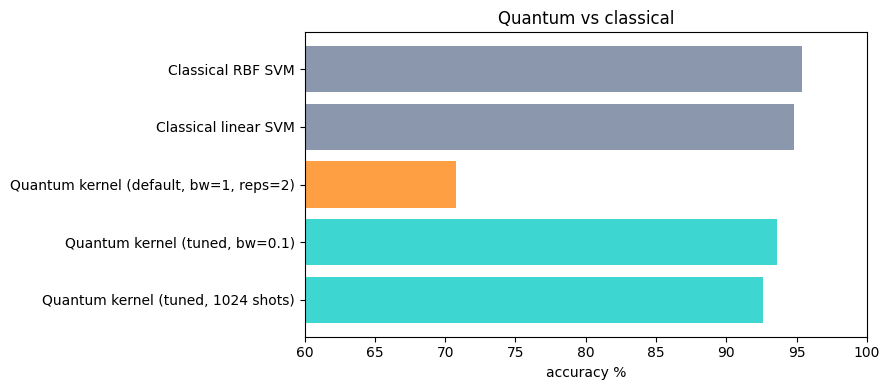

In [9]:
names = list(results); acc = [results[k][0] for k in names]
plt.figure(figsize=(9,4)); plt.barh(names, acc, color=['#8a97ad','#8a97ad','#ff9f43','#3dd6d0','#3dd6d0'])
plt.xlim(60,100); plt.xlabel('accuracy %'); plt.title('Quantum vs classical'); plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

## 6. Interpretation: kernel matrix and confusion matrix (one held-out fold)

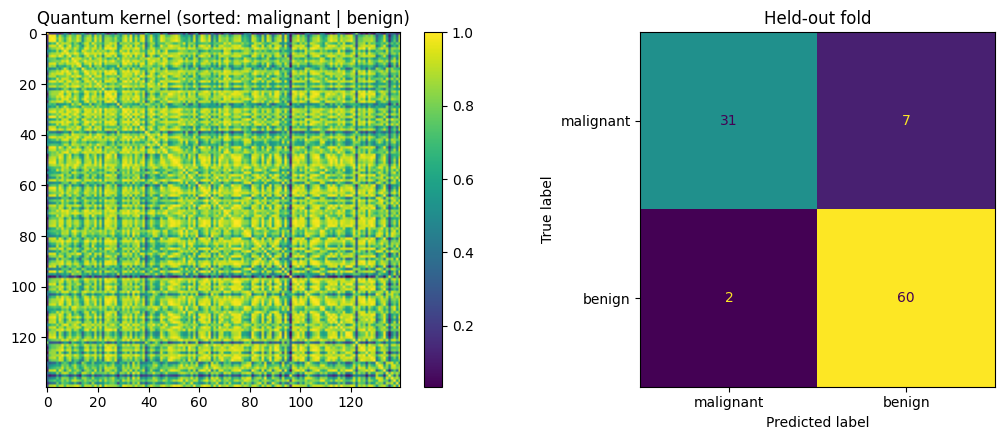

In [10]:
tr, te = splits[0]; A, B = prep(X[tr], X[te]); A, B = A*BW, B*BW
order = np.argsort(y[tr]); K = qkernel(feature_map(), A, A)[np.ix_(order, order)]
pr = quantum(feature_map(), BW)(tr, te)
fig, ax = plt.subplots(1, 2, figsize=(11,4.5))
im = ax[0].imshow(K, cmap='viridis'); ax[0].set_title('Quantum kernel (sorted: malignant | benign)'); plt.colorbar(im, ax=ax[0])
ConfusionMatrixDisplay(confusion_matrix(y[te], pr), display_labels=['malignant','benign']).plot(ax=ax[1], colorbar=False)
ax[1].set_title('Held-out fold'); plt.tight_layout(); plt.show()

## 7. Noisy-hardware emulation (optional, takes about a minute)
Gate noise via Aer's depolarizing model on a small subset, to check the kernel survives realistic errors.

In [11]:
from qiskit_aer.noise import NoiseModel, depolarizing_error
nm = NoiseModel(); nm.add_all_qubit_quantum_error(depolarizing_error(0.001,1), ['u','u1','u2','u3','h','s','sdg','x','z','p','rz','sx'])
nm.add_all_qubit_quantum_error(depolarizing_error(0.01,2), ['cx','cp'])
noisy = AerSimulator(noise_model=nm)
def noisy_kernel(fm, A, B, shots=512):
    K = np.zeros((len(A), len(B)))
    circs = []
    for a in A:
        for b in B:
            q = QuantumCircuit(4); q.compose(fm.assign_parameters(a), inplace=True); q.compose(fm.assign_parameters(b).inverse(), inplace=True); q.measure_all()
            circs.append(q.decompose().decompose())
    from qiskit import transpile
    circs = transpile(circs, noisy, optimization_level=1)
    res = noisy.run(circs, shots=shots).result()
    for i in range(len(circs)): K[i//len(B), i%len(B)] = res.get_counts(i).get('0000', 0)/shots
    return K
sub_tr, sub_te = tr[:50], te[:40]
A, B = prep(X[sub_tr], X[sub_te]); A, B = A*BW, B*BW
Ktr, Kte = noisy_kernel(feature_map(), A, A), noisy_kernel(feature_map(), B, A)
Ktr = (Ktr + Ktr.T)/2; np.fill_diagonal(Ktr, 1)
pn = SVC(kernel='precomputed', C=3).fit(Ktr, y[sub_tr]).predict(Kte)
Kex = qkernel(feature_map(), A, A); pe = SVC(kernel='precomputed', C=3).fit(Kex, y[sub_tr]).predict(qkernel(feature_map(), B, A))
print('noiseless accuracy:', accuracy_score(y[sub_te], pe)*100, '| noisy accuracy:', accuracy_score(y[sub_te], pn)*100)

noiseless accuracy: 85.0 | noisy accuracy: 85.0


## Conclusions
- A **default** quantum kernel overfits the feature space (~71%); a **bandwidth-tuned, one-repetition** kernel reaches classical parity (~93.6%).
- The circuit is shallow (4 qubits, depth ~11, 6 CNOTs) and robust to shot and gate noise in simulation.
- **Honest limits:** parity, not quantum advantage; malignant recall is slightly below the RBF SVM; results are simulator-based.
- **Next steps:** run on IBM hardware with error mitigation, class-weighted SVM to raise recall, larger feature counts.